# Dự đoán AQI trung bình ngày tiếp theo tại Hà Nội

## Giới thiệu và phạm vi

**Đề tài:** Phân tích chất lượng không khí Hà Nội 2022–2025 và hệ thống dự đoán AQI.

**Mục tiêu dự đoán:** từ AQI trung bình của **7 ngày lịch liên tiếp ngay trước ngày đích**, dự đoán AQI trung bình của ngày đích. `AQI_lag_1` là ngày liền trước; `AQI_lag_7` là ngày cách ngày đích bảy ngày. Biến mục tiêu là `AQI_target`, tức AQI trung bình ngày đích.

**Dữ liệu:** `output/data/aqi_hanoi_cleaned.csv` do Notebook 1 tạo từ bốn CSV 2022–2025. Phạm vi quan sát 13/01/2022–30/06/2025; 2025 chỉ có sáu tháng. Ngày 31/12/2023 không có bản ghi, 01/07/2022 và 01/12/2024 thiếu AQI theo giờ. Giữ NaN và cực trị đã được Notebook 1 xác nhận; không thay đổi file đã làm sạch.

**Quy tắc giai đoạn này:** ngày chỉ hợp lệ nếu có 24 mốc giờ duy nhất và 24 giờ AQI hợp lệ. Không điền hoặc nội suy ngày thiếu. Chỉ tạo bảy lag AQI để đầu vào khi sử dụng đúng với lúc chuẩn bị dữ liệu. Chia train/validation/test theo thời gian.

**Dự kiến giai đoạn sau:** so sánh baseline với Ridge Regression bằng MAE và RMSE, chỉ chọn mô hình sau đánh giá thực tế. Notebook này ở Giai đoạn 9 **chỉ chuẩn bị dữ liệu**, chưa huấn luyện, đánh giá hoặc xây dựng chức năng dự đoán.

### Bước 9.1 — Đọc và kiểm tra dữ liệu đã làm sạch

**Mục tiêu:** Xác nhận cấu trúc, thời gian, AQI thiếu và tính duy nhất/liên tục của giờ.

**Lý do:** Mọi phép tổng hợp ngày phải bắt đầu từ nguồn đã kiểm chứng; giờ không có dòng khác ô AQI thiếu.

**Phương pháp:** Đọc CSV với parse_dates, kiểm tra shape/dtypes/phạm vi, giờ trùng và giờ vắng trong khoảng quan sát.

**Kết quả cần quan sát:** Số hàng/cột, AQI thiếu và khoảng giờ không có bản ghi.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display

project_root=Path.cwd().resolve()
if not (project_root/'output/data/aqi_hanoi_cleaned.csv').exists():
    project_root=project_root.parent
data_path=project_root/'output/data/aqi_hanoi_cleaned.csv'
assert data_path.is_file(),data_path
cleaned_hash_before=hashlib.sha256(data_path.read_bytes()).hexdigest()
hourly=pd.read_csv(data_path,parse_dates=['Local Time','UTC Time'])
print('shape',hourly.shape)
print('dtypes');print(hourly.dtypes.to_string())
print('Local Time range',hourly['Local Time'].min(),hourly['Local Time'].max())
print('AQI missing',int(hourly['AQI'].isna().sum()))
print('unique timestamps',hourly['Local Time'].nunique(),'duplicate timestamps',int(hourly['Local Time'].duplicated().sum()))
calendar_hours=pd.date_range(hourly['Local Time'].min(),hourly['Local Time'].max(),freq='h')
missing_hours=calendar_hours.difference(pd.DatetimeIndex(hourly['Local Time']))
print('unrecorded hours',len(missing_hours),'first',missing_hours.min() if len(missing_hours) else None,'last',missing_hours.max() if len(missing_hours) else None)
assert hourly.shape[1]==19 and hourly['Local Time'].is_unique

shape (30336, 19)
dtypes
Local Time                datetime64[us]
UTC Time             datetime64[us, UTC]
City                                 str
Country code                         str
timezone                             str
AQI                              float64
CO                               float64
NO2                              float64
O3                               float64
PM10                             float64
PM25                             float64
SO2                              float64
Clouds                           float64
Precipitation                    float64
Pressure                         float64
Relative Humidity                float64
Temperature                      float64
UV Index                         float64
Wind Speed                       float64
Local Time range 2022-01-13 00:00:00 2025-06-30 23:00:00
AQI missing 3
unique timestamps 30336 duplicate timestamps 0
unrecorded hours 24 first 2023-12-31 00:00:00 last 2023-12-31 23:00:00


### Kết luận bước 9.1

File đã làm sạch đọc lại có 30.336 dòng × 19 cột. `Local Time` và `UTC Time` được parse thành thời gian (UTC Time có múi giờ UTC); AQI và các biến số là `float64`, cột định danh là chuỗi. Phạm vi Local Time là 13/01/2022 00:00–30/06/2025 23:00. Có 3 ô AQI thiếu, 30.336 mốc giờ duy nhất và không còn giờ trùng. Đối chiếu lịch giờ trong khoảng quan sát cho thấy thiếu đúng 24 giờ từ 31/12/2023 00:00 đến 23:00; không có bản ghi cho ngày đó. Bước tiếp theo sẽ lập lịch ngày đầy đủ để không vô tình nối qua khoảng trống.

### Bước 9.2 — Tổng hợp AQI theo lịch ngày và đánh dấu ngày không hợp lệ

**Mục tiêu:** Tạo AQI trung bình ngày và phân biệt ngày thiếu bản ghi với ngày thiếu AQI.

**Lý do:** Chỉ ngày có đủ 24 mốc giờ và 24 giờ AQI hợp lệ mới được dùng làm đầu vào hoặc mục tiêu.

**Phương pháp:** Groupby ngày theo Local Time; reindex lịch đầy đủ; đếm mốc giờ, AQI hợp lệ và tính mean; gắn nhãn trạng thái.

**Kết quả cần quan sát:** Số ngày hợp lệ/không hợp lệ và bảng từng ngày không hợp lệ.

In [2]:
hourly=hourly.sort_values('Local Time').copy()
hourly['date']=hourly['Local Time'].dt.normalize()
daily=hourly.groupby('date').agg(recorded_hours=('Local Time','nunique'),valid_aqi_hours=('AQI','count'),aqi_mean_observed=('AQI','mean'))
calendar_days=pd.date_range(daily.index.min(),daily.index.max(),freq='D',name='date')
daily=daily.reindex(calendar_days)
daily[['recorded_hours','valid_aqi_hours']]=daily[['recorded_hours','valid_aqi_hours']].fillna(0).astype(int)
daily['valid_day']=(daily['recorded_hours']==24)&(daily['valid_aqi_hours']==24)
daily['AQI_daily']=daily['aqi_mean_observed'].where(daily['valid_day'])
daily['status']=np.select([daily['recorded_hours']==0,daily['recorded_hours']!=24,daily['valid_aqi_hours']!=24],['không có bản ghi','không đủ 24 mốc giờ','thiếu AQI trong giờ có bản ghi'],default='hợp lệ')
print('calendar days',len(daily),'valid',int(daily['valid_day'].sum()),'invalid',int((~daily['valid_day']).sum()))
print('invalid days');print(daily.loc[~daily['valid_day'],['recorded_hours','valid_aqi_hours','aqi_mean_observed','AQI_daily','status']].to_string())
print('valid daily AQI range',daily['AQI_daily'].min(),daily['AQI_daily'].max())
assert (daily.loc[daily['valid_day'],'recorded_hours']==24).all()
assert (daily.loc[daily['valid_day'],'valid_aqi_hours']==24).all()

calendar days 1265 valid 1262 invalid 3
invalid days
            recorded_hours  valid_aqi_hours  aqi_mean_observed  AQI_daily                          status
date                                                                                                     
2022-07-01              24               22          90.181818        NaN  thiếu AQI trong giờ có bản ghi
2023-12-31               0                0                NaN        NaN                không có bản ghi
2024-12-01              24               23         160.826087        NaN  thiếu AQI trong giờ có bản ghi
valid daily AQI range 42.875 500.0


### Kết luận bước 9.2

Lịch từ 13/01/2022 đến 30/06/2025 gồm 1.265 ngày: 1.262 ngày hợp lệ và 3 ngày không hợp lệ. Ngày 01/07/2022 có đủ 24 mốc giờ nhưng chỉ 22 giờ AQI hợp lệ; ngày 01/12/2024 có 24 mốc giờ và 23 giờ AQI; ngày 31/12/2023 không có bản ghi. Dù hai ngày thiếu AQI có thể tính trung bình từ 22 hoặc 23 giờ quan sát (90,182 và 160,826), cột `AQI_daily` dùng cho dự đoán được đặt NaN theo quy tắc đủ 24 giờ đã xác nhận; không điền hay nội suy. AQI ngày hợp lệ nằm trong 42,875–500,0. Bước sau tạo lag trên toàn bộ lịch ngày, để cả ba ngày này làm gián đoạn cửa sổ.

### Bước 9.3 — Tạo bảy lag và lọc cửa sổ tám ngày hợp lệ

**Mục tiêu:** Tạo đầu vào từ đúng bảy ngày lịch ngay trước ngày đích.

**Lý do:** Dịch trên lịch đủ ngày giữ gián đoạn, không nối các ngày có dữ liệu qua khoảng trống.

**Phương pháp:** Tạo shift(1)…shift(7) từ AQI_daily chỉ của ngày hợp lệ; giữ mẫu khi ngày đích và cả bảy lag đều hợp lệ; ghi lý do loại.

**Kết quả cần quan sát:** Số mẫu cuối, số ngày bị loại và nguyên nhân.

In [3]:
lag_columns=[f'AQI_lag_{k}' for k in range(1,8)]
candidates=pd.DataFrame(index=daily.index)
for k,col in enumerate(lag_columns,1):
    candidates[col]=daily['AQI_daily'].shift(k)
candidates['AQI_target']=daily['AQI_daily']
candidates['target_valid']=daily['valid_day']
candidates['valid_window']=candidates['target_valid']&candidates[lag_columns].notna().all(axis=1)
def invalid_reason(day,row):
    if row['valid_window']:
        return 'hợp lệ'
    if not row['target_valid']:
        return daily.loc[day,'status']+' ở ngày đích'
    for k,col in enumerate(lag_columns,1):
        if pd.isna(row[col]):
            previous_day=day-pd.Timedelta(days=k)
            if previous_day<daily.index.min():
                return 'thiếu lịch sử trước ngày bắt đầu'
            return f'lag_{k}: {previous_day.date()} {daily.loc[previous_day,"status"]}'
    raise AssertionError('Không tìm thấy lý do loại')
invalid_detail=candidates.loc[~candidates['valid_window']].copy()
invalid_detail['reason']=[invalid_reason(day,row) for day,row in invalid_detail.iterrows()]
prediction_data=candidates.loc[candidates['valid_window'],lag_columns+['AQI_target']].copy()
prediction_data.index.name='target_date'
print('candidate dates',len(candidates),'valid prediction samples',len(prediction_data),'excluded',len(invalid_detail))
print('excluded target dates and reasons');print(invalid_detail[['reason']].to_string())
print('prediction range',prediction_data.index.min(),prediction_data.index.max())
assert not prediction_data.isna().any().any()

candidate dates 1265 valid prediction samples 1234 excluded 31
excluded target dates and reasons
                                                      reason
date                                                        
2022-01-13                  thiếu lịch sử trước ngày bắt đầu
2022-01-14                  thiếu lịch sử trước ngày bắt đầu
2022-01-15                  thiếu lịch sử trước ngày bắt đầu
2022-01-16                  thiếu lịch sử trước ngày bắt đầu
2022-01-17                  thiếu lịch sử trước ngày bắt đầu
2022-01-18                  thiếu lịch sử trước ngày bắt đầu
2022-01-19                  thiếu lịch sử trước ngày bắt đầu
2022-07-01        thiếu AQI trong giờ có bản ghi ở ngày đích
2022-07-02  lag_1: 2022-07-01 thiếu AQI trong giờ có bản ghi
2022-07-03  lag_2: 2022-07-01 thiếu AQI trong giờ có bản ghi
2022-07-04  lag_3: 2022-07-01 thiếu AQI trong giờ có bản ghi
2022-07-05  lag_4: 2022-07-01 thiếu AQI trong giờ có bản ghi
2022-07-06  lag_5: 2022-07-01 thiếu AQI trong giờ

### Kết luận bước 9.3

Trên 1.265 ngày lịch ứng viên, giữ được 1.234 mẫu có ngày đích và cả bảy ngày liền trước hợp lệ; loại 31 ngày đích. Trong đó 7 ngày đầu 13–19/01/2022 thiếu lịch sử trước khi dữ liệu bắt đầu; mỗi ngày không hợp lệ 01/07/2022, 31/12/2023, 01/12/2024 loại chính ngày đó và bảy ngày kế tiếp (8 × 3 = 24). Mẫu đầu là 20/01/2022, mẫu cuối 30/06/2025. Bảng in rõ ngày bị loại và lag hoặc ngày đích gây loại; việc `shift(k)` trên lịch ngày đầy đủ không nối bảy ngày có dữ liệu qua khoảng trống. Không điền NaN hay dùng ngày không đủ giờ.

### Bước 9.4 — Kiểm tra lag bằng ngày cụ thể

**Mục tiêu:** Xác minh thứ tự lag và việc không vượt qua ngày gián đoạn.

**Lý do:** Tên cột chưa đủ chứng minh không dùng tương lai; cần so ngày đích với dữ liệu lịch thực.

**Phương pháp:** Hiển thị mẫu đầu/cuối và đối chiếu vài ngày quanh ba gián đoạn; assert từng lag trùng ngày đích trừ k ngày.

**Kết quả cần quan sát:** Mẫu kiểm chứng và trạng thái các ngày sát gián đoạn.

In [4]:
print('FIRST 3 SAMPLES');display(prediction_data.head(3).round(3))
print('LAST 3 SAMPLES');display(prediction_data.tail(3).round(3))
check_dates=pd.to_datetime(['2022-01-20','2022-07-01','2022-07-02','2022-07-08','2022-07-09','2023-12-31','2024-01-01','2024-01-07','2024-01-08','2024-12-01','2024-12-02','2024-12-08','2024-12-09'])
print('GAP BOUNDARY CHECK');print(pd.DataFrame({'daily_valid':daily.loc[check_dates,'valid_day'],'sample_kept':candidates.loc[check_dates,'valid_window']}).to_string())
for target in [prediction_data.index[0],pd.Timestamp('2022-07-09'),pd.Timestamp('2024-01-08'),pd.Timestamp('2024-12-09'),prediction_data.index[-1]]:
    row=prediction_data.loc[target]
    for k,col in enumerate(lag_columns,1):
        past_day=target-pd.Timedelta(days=k)
        assert daily.loc[past_day,'valid_day'] and np.isclose(row[col],daily.loc[past_day,'AQI_daily'])
    assert np.isclose(row['AQI_target'],daily.loc[target,'AQI_daily'])
    print('checked',target.date(),'lag_1 date',(target-pd.Timedelta(days=1)).date(),'lag_7 date',(target-pd.Timedelta(days=7)).date(),'target',round(row['AQI_target'],3),'lag_1',round(row['AQI_lag_1'],3))

FIRST 3 SAMPLES


,AQI_lag_1,AQI_lag_2,AQI_lag_3,AQI_lag_4,AQI_lag_5,AQI_lag_6,AQI_lag_7,AQI_target
target_date,,,,,,,,
2022-01-20,184.542,129.917,117.042,153.583,176.750,203.792,176.500,157.875
2022-01-21,157.875,184.542,129.917,117.042,153.583,176.750,203.792,178.042
2022-01-22,178.042,157.875,184.542,129.917,117.042,153.583,176.750,168.542


LAST 3 SAMPLES


,AQI_lag_1,AQI_lag_2,AQI_lag_3,AQI_lag_4,AQI_lag_5,AQI_lag_6,AQI_lag_7,AQI_target
target_date,,,,,,,,
2025-06-28,93.083,100.417,98.250,126.917,112.708,94.708,89.708,85.958
2025-06-29,85.958,93.083,100.417,98.250,126.917,112.708,94.708,111.167
2025-06-30,111.167,85.958,93.083,100.417,98.250,126.917,112.708,88.792


GAP BOUNDARY CHECK
            daily_valid  sample_kept
date                                
2022-01-20         True         True
2022-07-01        False        False
2022-07-02         True        False
2022-07-08         True        False
2022-07-09         True         True
2023-12-31        False        False
2024-01-01         True        False
2024-01-07         True        False
2024-01-08         True         True
2024-12-01        False        False
2024-12-02         True        False
2024-12-08         True        False
2024-12-09         True         True
checked 2022-01-20 lag_1 date 2022-01-19 lag_7 date 2022-01-13 target 157.875 lag_1 184.542
checked 2022-07-09 lag_1 date 2022-07-08 lag_7 date 2022-07-02 target 95.875 lag_1 84.292
checked 2024-01-08 lag_1 date 2024-01-07 lag_7 date 2024-01-01 target 138.167 lag_1 134.25
checked 2024-12-09 lag_1 date 2024-12-08 lag_7 date 2024-12-02 target 163.417 lag_1 101.958
checked 2025-06-30 lag_1 date 2025-06-29 lag_7 date 2025-06-2

### Kết luận bước 9.4

Ba mẫu đầu và cuối hiển thị đúng `target_date`, bảy lag và `AQI_target`. Ví dụ mẫu đích 20/01/2022 dùng `lag_1` từ 19/01 (184,542), `lag_7` từ 13/01 và mục tiêu 157,875 của 20/01; mẫu cuối 30/06/2025 dùng `lag_1` của 29/06 (111,167) và `lag_7` của 23/06, mục tiêu 88,792. Kiểm tra ngày gián đoạn cho thấy 01/07/2022, 31/12/2023, 01/12/2024 và bảy ngày theo sau đều không thành mẫu; các mẫu đầu tiên sau đó là 09/07/2022, 08/01/2024 và 09/12/2024. Các assert đối chiếu lag và mục tiêu với AQI ngày ở đúng ngày lịch đều qua; không có mẫu vượt qua ngày không hợp lệ.

### Bước 9.5 — Kiểm tra tính hợp lệ và rò rỉ thông tin

**Mục tiêu:** Xác nhận bảy đặc trưng chỉ dùng quá khứ, không thiếu và ngày đích tăng theo thời gian.

**Lý do:** Dataset cho học máy chỉ đáng tin khi mọi cửa sổ đủ tám ngày liên tiếp và không chứa AQI tương lai.

**Phương pháp:** Kiểm tra schema, NaN, index, nguồn từng lag trên toàn bộ mẫu và số ngày khác nhau.

**Kết quả cần quan sát:** Bảng kiểm tra nhất quán, số mẫu, số đặc trưng và số giá trị thiếu.

In [5]:
assert lag_columns==[c for c in prediction_data.columns if c.startswith('AQI_lag_')]
assert prediction_data.columns.tolist()==lag_columns+['AQI_target']
assert prediction_data.index.is_unique and prediction_data.index.is_monotonic_increasing
assert prediction_data.notna().all().all()
for k,col in enumerate(lag_columns,1):
    expected_lag=daily['AQI_daily'].shift(k).reindex(prediction_data.index)
    assert np.allclose(prediction_data[col].to_numpy(),expected_lag.to_numpy())
assert np.allclose(prediction_data['AQI_target'].to_numpy(),daily['AQI_daily'].reindex(prediction_data.index).to_numpy())
print('samples',len(prediction_data),'input features',len(lag_columns),'target columns',1,'missing cells',int(prediction_data.isna().sum().sum()))
print('target dates unique',prediction_data.index.nunique(),'time sorted',prediction_data.index.is_monotonic_increasing)
print('all seven lags equal AQI_daily on exact preceding calendar days: True')
print('future variables in feature list:',[c for c in lag_columns if c not in prediction_data.columns])

samples 1234 input features 7 target columns 1 missing cells 0
target dates unique 1234 time sorted True
all seven lags equal AQI_daily on exact preceding calendar days: True
future variables in feature list: []


### Kết luận bước 9.5

Bộ mẫu có 1.234 ngày đích duy nhất, sắp tăng theo thời gian, đúng 7 cột đầu vào `AQI_lag_1`…`AQI_lag_7` và một cột mục tiêu `AQI_target`; không có ô thiếu. Phép assert trên toàn bộ mẫu xác nhận mỗi `AQI_lag_k` bằng AQI ngày hợp lệ ở đúng ngày đích trừ k ngày, còn mục tiêu bằng AQI của ngày đích. Danh sách đặc trưng không chứa AQI ngày đích, ngày tương lai, thời tiết hay chất ô nhiễm. Đây là kiểm tra cấu trúc chống rò rỉ ở giai đoạn chuẩn bị; khi huấn luyện vẫn phải giữ thứ tự thời gian và fit mọi biến đổi chỉ trên train.

### Bước 9.6 — Thiết kế chia Train/Validation/Test theo thời gian

**Mục tiêu:** Đề xuất các tập dữ liệu theo ngày đích, chưa fit hoặc đánh giá mô hình.

**Lý do:** Cần bảo vệ tập test khỏi lựa chọn mô hình và ghi giới hạn mùa của 2025.

**Phương pháp:** Gán train cho ngày đích 2022–2023, validation 2024, test 01–06/2025; đếm mẫu và kiểm tra thứ tự.

**Kết quả cần quan sát:** Bảng số mẫu, phạm vi ngày đích và tỷ lệ; không chia ngẫu nhiên.

In [6]:
split_label=pd.Series(index=prediction_data.index,dtype='str')
split_label.loc[split_label.index<pd.Timestamp('2024-01-01')]='train'
split_label.loc[(split_label.index>=pd.Timestamp('2024-01-01'))&(split_label.index<pd.Timestamp('2025-01-01'))]='validation'
split_label.loc[split_label.index>=pd.Timestamp('2025-01-01')]='test'
split_summary=split_label.groupby(split_label).agg(['size'])
split_summary['first_target']=[split_label[split_label==name].index.min().date() for name in split_summary.index]
split_summary['last_target']=[split_label[split_label==name].index.max().date() for name in split_summary.index]
split_summary['pct_samples']=100*split_summary['size']/len(prediction_data)
print(split_summary.reindex(['train','validation','test']).round(2).to_string())
assert split_label.notna().all()
assert split_label[split_label=='train'].index.max()<split_label[split_label=='validation'].index.min()<split_label[split_label=='test'].index.min()
print('random split used: False; model fit or metric calculation: False')
print('2025 test months',sorted(split_label[split_label=='test'].index.month.unique().tolist()))

            size first_target last_target  pct_samples
train        702   2022-01-20  2023-12-30        56.89
validation   351   2024-01-08  2024-12-31        28.44
test         181   2025-01-01  2025-06-30        14.67
random split used: False; model fit or metric calculation: False
2025 test months [1, 2, 3, 4, 5, 6]


### Kết luận bước 9.6

Phương án chia theo ngày đích tăng dần: train 702 mẫu từ 20/01/2022 đến 30/12/2023 (56,89%); validation 351 mẫu từ 08/01 đến 31/12/2024 (28,44%); test 181 mẫu từ 01/01 đến 30/06/2025 (14,67%). Validation bắt đầu 08/01 vì thiếu toàn bộ 31/12/2023 làm bảy ngày đầu năm không đủ lag. Lag của các mẫu sát ranh giới có thể lấy AQI quá khứ đã xảy ra ở giai đoạn trước; ngày đích và mục tiêu của validation/test không được dùng để fit hoặc chọn mô hình. Tập test 2025 chỉ có tháng 1–6 nên không đại diện mọi mùa; chưa huấn luyện, tính MAE/RMSE hay chọn mô hình.

### Bước 9.7 — Lưu và đọc lại bộ dữ liệu dự đoán

**Mục tiêu:** Lưu mẫu lag7 để giai đoạn huấn luyện có đầu vào tái lập.

**Lý do:** Cần kiểm tra file đầu ra đúng schema và không ghi đè dữ liệu đã làm sạch.

**Phương pháp:** Lưu target_date, bảy lag, AQI_target vào CSV mới; đọc lại và so giá trị, hash file sạch.

**Kết quả cần quan sát:** Đường dẫn, kích thước file, schema và trạng thái bảo toàn file sạch.

In [7]:
prediction_path=project_root/'output/data/aqi_next_day_lag7.csv'
prediction_data.to_csv(prediction_path,index_label='target_date')
reloaded=pd.read_csv(prediction_path,parse_dates=['target_date']).set_index('target_date')
assert reloaded.shape==prediction_data.shape and reloaded.columns.tolist()==prediction_data.columns.tolist()
assert reloaded.index.equals(prediction_data.index)
assert np.allclose(reloaded.to_numpy(),prediction_data.to_numpy())
cleaned_hash_after=hashlib.sha256(data_path.read_bytes()).hexdigest()
assert cleaned_hash_before==cleaned_hash_after
print('saved',prediction_path.relative_to(project_root),'shape',reloaded.shape,'bytes',prediction_path.stat().st_size)
print('columns',reloaded.columns.tolist(),'target date range',reloaded.index.min(),reloaded.index.max())
print('missing cells',int(reloaded.isna().sum().sum()),'cleaned dataset unchanged',True)

saved output\data\aqi_next_day_lag7.csv shape (1234, 8) bytes 160981
columns ['AQI_lag_1', 'AQI_lag_2', 'AQI_lag_3', 'AQI_lag_4', 'AQI_lag_5', 'AQI_lag_6', 'AQI_lag_7', 'AQI_target'] target date range 2022-01-20 00:00:00 2025-06-30 00:00:00
missing cells 0 cleaned dataset unchanged True


### Kết luận bước 9.7

Đã lưu `output/data/aqi_next_day_lag7.csv` gồm 1.234 hàng, cột `target_date`, bảy cột `AQI_lag_1`…`AQI_lag_7` và `AQI_target` (8 cột số; tổng 9 cột CSV). Khi đọc lại, ngày đích, thứ tự cột và toàn bộ giá trị số khớp bộ nhớ; không có ô thiếu. Phạm vi ngày đích là 20/01/2022–30/06/2025. Hash của `aqi_hanoi_cleaned.csv` trước/sau bước lưu không đổi. File mới là đầu vào trung gian tái lập cho Giai đoạn 10; chưa chứa dự đoán, nhãn chia tập hay mô hình.

## Giai đoạn 10 — Huấn luyện và đánh giá dự đoán

So sánh Persistence (`AQI_lag_1`), Weekly (`AQI_lag_7`) và Ridge trên cùng mẫu Validation. **Tiêu chí lựa chọn được ấn định trước khi đánh giá Test:** MAE thấp nhất; RMSE chỉ phân xử khi MAE bằng nhau. Ridge chỉ thử alpha 0,1; 1; 10; 100. Nếu Ridge thắng, fit lại Pipeline StandardScaler–Ridge trên Train + Validation với alpha đã chọn, rồi đánh giá Test đúng một lần. Nếu baseline thắng, baseline đó là phương pháp cuối cùng và không cần fit. Mọi đặc trưng là AQI đã quan sát trước ngày đích; Test chỉ được dùng để đánh giá sau quyết định lựa chọn.

### Bước 10.1 — Đọc lại dữ liệu và khóa phân chia thời gian

**Mục tiêu:** Xác nhận file lag7, schema và số mẫu trước khi đánh giá.

**Lý do:** Không được tiếp tục nếu dữ liệu hoặc ranh giới tập khác Giai đoạn 9.

**Phương pháp:** Đọc CSV trung gian, kiểm tra thứ tự/NaN/7 lag, tách X/y theo ngày đích và assert số mẫu Train/Validation/Test.

**Kết quả cần quan sát:** Bảng kích thước, kiểu, thời gian và các kiểm tra đầu vào.

In [8]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

feature_names=[f'AQI_lag_{k}' for k in range(1,8)]
model_data=pd.read_csv(project_root/'output/data/aqi_next_day_lag7.csv',parse_dates=['target_date']).set_index('target_date')
assert model_data.shape==(1234,8)
assert model_data.columns.tolist()==feature_names+['AQI_target']
assert model_data.index.is_unique and model_data.index.is_monotonic_increasing
assert not model_data.isna().any().any()
assert all(pd.api.types.is_numeric_dtype(model_data[col]) for col in model_data.columns)
X=model_data[feature_names];y=model_data['AQI_target']
train_mask=model_data.index<pd.Timestamp('2024-01-01')
val_mask=(model_data.index>=pd.Timestamp('2024-01-01'))&(model_data.index<pd.Timestamp('2025-01-01'))
test_mask=model_data.index>=pd.Timestamp('2025-01-01')
X_train,y_train=X.loc[train_mask],y.loc[train_mask]
X_val,y_val=X.loc[val_mask],y.loc[val_mask]
X_test,y_test=X.loc[test_mask],y.loc[test_mask]
assert (len(X_train),len(X_val),len(X_test))==(702,351,181)
assert X_train.index.max()<X_val.index.min()<X_test.index.min()
print('shape',model_data.shape,'missing',int(model_data.isna().sum().sum()))
print('dtypes');print(model_data.dtypes.to_string())
print('features',feature_names,'target','AQI_target')
for name,frame in [('train',X_train),('validation',X_val),('test',X_test)]:print(name,len(frame),frame.index.min(),frame.index.max())
print('time sorted',model_data.index.is_monotonic_increasing,'target absent from X', 'AQI_target' not in X.columns)

shape (1234, 8) missing 0
dtypes
AQI_lag_1     float64
AQI_lag_2     float64
AQI_lag_3     float64
AQI_lag_4     float64
AQI_lag_5     float64
AQI_lag_6     float64
AQI_lag_7     float64
AQI_target    float64
features ['AQI_lag_1', 'AQI_lag_2', 'AQI_lag_3', 'AQI_lag_4', 'AQI_lag_5', 'AQI_lag_6', 'AQI_lag_7'] target AQI_target
train 702 2022-01-20 00:00:00 2023-12-30 00:00:00
validation 351 2024-01-08 00:00:00 2024-12-31 00:00:00
test 181 2025-01-01 00:00:00 2025-06-30 00:00:00
time sorted True target absent from X True


### Kết luận bước 10.1

File lag7 có 1.234 mẫu, bảy đặc trưng `AQI_lag_1`…`AQI_lag_7` và `AQI_target`, tất cả `float64`, không có ô thiếu; ngày đích duy nhất và tăng theo thời gian. `AQI_target` không nằm trong ma trận đặc trưng X. Chia theo ngày đích khớp Giai đoạn 9: Train 702 mẫu (20/01/2022–30/12/2023), Validation 351 (08/01–31/12/2024), Test 181 (01/01–30/06/2025). Các khoảng không chồng nhau. Có thể tính baseline trên Validation; chưa dùng Test để chọn phương pháp.

### Bước 10.2 — Hai baseline trên Validation

**Mục tiêu:** Tạo mốc so sánh không cần fit trên dữ liệu Validation.

**Lý do:** Mô hình Ridge chỉ có ý nghĩa nếu so được với cách dự đoán đơn giản.

**Phương pháp:** Persistence lấy lag1, Weekly lấy lag7; tính MAE và RMSE trên cùng 351 ngày Validation.

**Kết quả cần quan sát:** Bảng lỗi của hai baseline trên Validation.

In [9]:
def score_predictions(actual,prediction):
    return {'n':len(actual),'MAE':mean_absolute_error(actual,prediction),'RMSE':np.sqrt(mean_squared_error(actual,prediction))}
val_predictions={'Persistence':X_val['AQI_lag_1'].to_numpy(),'Weekly':X_val['AQI_lag_7'].to_numpy()}
baseline_validation=pd.DataFrame({name:score_predictions(y_val,pred) for name,pred in val_predictions.items()}).T
print(baseline_validation.round(3).to_string())
print('baseline fitted:',False,'validation target used as feature:',False)

                 n     MAE    RMSE
Persistence  351.0  24.818  38.729
Weekly       351.0  41.253  58.372
baseline fitted: False validation target used as feature: False


### Kết luận bước 10.2

Trên cùng 351 ngày Validation, Persistence đạt MAE 24,818 và RMSE 38,729; Weekly có MAE 41,253 và RMSE 58,372. Persistence tốt hơn Weekly 16,435 điểm MAE và 19,643 điểm RMSE. Hai baseline lấy trực tiếp `AQI_lag_1` hoặc `AQI_lag_7`, không fit tham số và không dùng AQI ngày đích làm đầu vào. Persistence là mốc cần vượt khi so Ridge.

### Bước 10.3 — Ridge và chọn alpha trên Validation

**Mục tiêu:** So sánh bốn mức regularization bằng cùng Train/Validation.

**Lý do:** StandardScaler phải học tham số từ Train; Test chưa được dùng.

**Phương pháp:** Với từng alpha 0,1; 1; 10; 100, fit Pipeline(StandardScaler,Ridge) trên Train, dự đoán Validation và tính MAE/RMSE.

**Kết quả cần quan sát:** Bảng alpha và sai số; alpha được chọn bằng MAE rồi RMSE.

In [10]:
alpha_grid=[0.1,1.0,10.0,100.0]
ridge_trials=[]
for alpha in alpha_grid:
    trial=Pipeline([('scaler',StandardScaler()),('ridge',Ridge(alpha=alpha))])
    trial.fit(X_train,y_train)
    prediction=trial.predict(X_val)
    ridge_trials.append({'alpha':alpha,**score_predictions(y_val,prediction)})
ridge_tuning=pd.DataFrame(ridge_trials).sort_values(['MAE','RMSE','alpha']).reset_index(drop=True)
chosen_alpha=float(ridge_tuning.iloc[0]['alpha'])
print(ridge_tuning.round(4).to_string(index=False))
print('chosen alpha',chosen_alpha,'rule=lowest validation MAE, then RMSE')
print('scaler fitted only inside pipeline on 702 Train samples; Test not used')

 alpha   n     MAE    RMSE
   0.1 351 23.3883 34.8658
   1.0 351 23.3978 34.8746
  10.0 351 23.4925 34.9690
 100.0 351 24.4033 35.9880
chosen alpha 0.1 rule=lowest validation MAE, then RMSE
scaler fitted only inside pipeline on 702 Train samples; Test not used


### Kết luận bước 10.3

Ridge với Pipeline StandardScaler→Ridge được fit riêng trên 702 mẫu Train cho từng alpha. Trên 351 mẫu Validation, alpha 0,1 đạt MAE 23,3883 và RMSE 34,8658; alpha 1 đạt 23,3978/34,8746; alpha 10 đạt 23,4925/34,9690; alpha 100 đạt 24,4033/35,9880. Theo quy tắc MAE thấp nhất rồi RMSE, chọn alpha = 0,1. StandardScaler chỉ học trên Train trong các lần thử; Test chưa tham gia lựa chọn alpha.

### Bước 10.4 — So sánh và chọn phương pháp trên Validation

**Mục tiêu:** Chọn Persistence, Weekly hoặc Ridge từ cùng Validation trước khi mở Test.

**Lý do:** Không mặc định Ridge thắng; việc chọn theo MAE rồi RMSE được công bố trước.

**Phương pháp:** Tính Ridge Validation với alpha đã chọn, lập bảng n/MAE/RMSE và chênh so Persistence; cố định phương pháp.

**Kết quả cần quan sát:** Bảng so sánh ba phương pháp và quyết định cuối trước Test.

In [11]:
selected_train_pipeline=Pipeline([('scaler',StandardScaler()),('ridge',Ridge(alpha=chosen_alpha))])
selected_train_pipeline.fit(X_train,y_train)
val_predictions['Ridge']=selected_train_pipeline.predict(X_val)
validation_table=pd.DataFrame({name:score_predictions(y_val,pred) for name,pred in val_predictions.items()}).T
validation_table['MAE_minus_Persistence']=validation_table['MAE']-validation_table.loc['Persistence','MAE']
validation_table['RMSE_minus_Persistence']=validation_table['RMSE']-validation_table.loc['Persistence','RMSE']
validation_table=validation_table.sort_values(['MAE','RMSE'])
selected_method=str(validation_table.index[0])
print(validation_table.round(4).to_string())
print('SELECTED ON VALIDATION',selected_method,'alpha',chosen_alpha if selected_method=='Ridge' else 'not applicable')
print('TEST NOT USED TO SELECT',True)

                 n      MAE     RMSE  MAE_minus_Persistence  RMSE_minus_Persistence
Ridge        351.0  23.3883  34.8658                -1.4299                 -3.8634
Persistence  351.0  24.8181  38.7292                 0.0000                  0.0000
Weekly       351.0  41.2527  58.3719                16.4346                 19.6427
SELECTED ON VALIDATION Ridge alpha 0.1
TEST NOT USED TO SELECT True


### Kết luận bước 10.4

Bảng Validation trên 351 mẫu xếp Ridge (alpha 0,1) đầu: MAE 23,3883, RMSE 34,8658; Persistence 24,8181/38,7292; Weekly 41,2527/58,3719. Ridge thấp hơn Persistence 1,4299 MAE và 3,8634 RMSE. Theo tiêu chí đã ấn định MAE rồi RMSE, chọn **Ridge alpha 0,1** trước khi đánh giá Test. Chênh này chứng minh Ridge tốt hơn hai baseline trên Validation của giai đoạn này, chưa chứng minh kết quả Test.

### Bước 10.5 — Đánh giá Test sau khi cố định phương pháp

**Mục tiêu:** Đo sai số cuối trên Test chưa dùng để chọn phương pháp/alpha.

**Lý do:** Test chỉ được dùng để đánh giá sau quyết định Validation; mọi bước fit lại chỉ được dùng Train + Validation.

**Phương pháp:** Nếu Ridge thắng, fit lại pipeline trên Train+Validation; nếu baseline thắng, dùng công thức lag. Tính Test cho cả ba để đối chiếu, không chọn lại.

**Kết quả cần quan sát:** Bảng n/MAE/RMSE Test và phương pháp cuối đã cố định.

In [12]:
test_predictions={'Persistence':X_test['AQI_lag_1'].to_numpy(),'Weekly':X_test['AQI_lag_7'].to_numpy()}
X_train_val=pd.concat([X_train,X_val]);y_train_val=pd.concat([y_train,y_val])
final_ridge_pipeline=Pipeline([('scaler',StandardScaler()),('ridge',Ridge(alpha=chosen_alpha))])
final_ridge_pipeline.fit(X_train_val,y_train_val)
test_predictions['Ridge']=final_ridge_pipeline.predict(X_test)
final_predictor=final_ridge_pipeline if selected_method=='Ridge' else selected_method
test_table=pd.DataFrame({name:score_predictions(y_test,pred) for name,pred in test_predictions.items()}).T
test_table['MAE_minus_Persistence']=test_table['MAE']-test_table.loc['Persistence','MAE']
test_table['RMSE_minus_Persistence']=test_table['RMSE']-test_table.loc['Persistence','RMSE']
print('FINAL METHOD FIXED BEFORE TEST',selected_method)
print('Ridge alpha fixed',chosen_alpha,'Ridge refit on Train+Validation n',len(X_train_val),'including scaler')
print('If selected baseline, final predictor requires no fit; Ridge is evaluation comparator only.')
print(test_table.round(4).to_string())
print('test dates',X_test.index.min(),X_test.index.max(),'rolling one-step with observed prior seven AQI days')

FINAL METHOD FIXED BEFORE TEST Ridge
Ridge alpha fixed 0.1 Ridge refit on Train+Validation n 1053 including scaler
If selected baseline, final predictor requires no fit; Ridge is evaluation comparator only.
                 n      MAE     RMSE  MAE_minus_Persistence  RMSE_minus_Persistence
Persistence  181.0  24.7083  32.0491                 0.0000                  0.0000
Weekly       181.0  37.3027  49.1494                12.5944                 17.1002
Ridge        181.0  22.3992  29.6577                -2.3091                 -2.3915
test dates 2025-01-01 00:00:00 2025-06-30 00:00:00 rolling one-step with observed prior seven AQI days


### Kết luận bước 10.5

Sau khi cố định Ridge alpha 0,1 từ Validation, Pipeline gồm StandardScaler và Ridge được fit lại trên 1.053 mẫu Train + Validation; Test không tham gia fit. Trên 181 ngày Test (01/01–30/06/2025), Ridge đạt MAE 22,3992 và RMSE 29,6577; Persistence 24,7083/32,0491; Weekly 37,3027/49,1494. Ridge thấp hơn Persistence 2,3091 MAE và 2,3915 RMSE trên Test, đồng thời tốt hơn Weekly. Đây là đánh giá dự báo cuốn chiếu một ngày: mỗi ngày đích sử dụng bảy AQI ngày thực tế đã xảy ra trước đó, không phải dự báo nhiều ngày bằng cách đưa dự đoán ngược làm đầu vào. Kết quả Test không được dùng để đổi alpha hoặc phương pháp.

### Bước 10.6 — Biểu đồ dự đoán và sai số trên Test

**Mục tiêu:** Cho thấy diễn biến và phân phối sai số của phương pháp đã chọn.

**Lý do:** Chỉ số Test tính trên toàn bộ 181 ngày; hình đường dài cần khoảng cố định dễ đọc.

**Phương pháp:** Vẽ 45 ngày đầu Test (chọn trước để minh họa) và histogram sai số ký hiệu dự đoán trừ thực tế trên toàn bộ Test.

**Kết quả cần quan sát:** Hai hình có tiêu đề, nhãn, phạm vi và số mẫu.

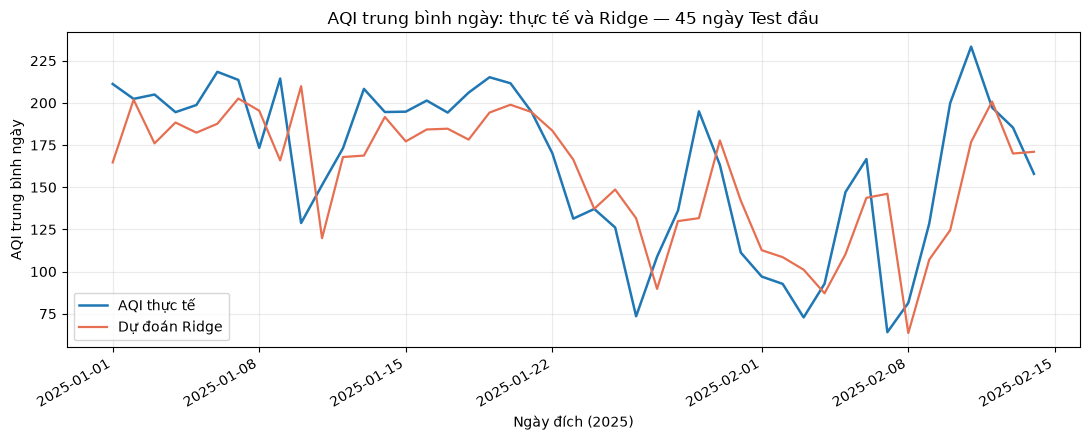

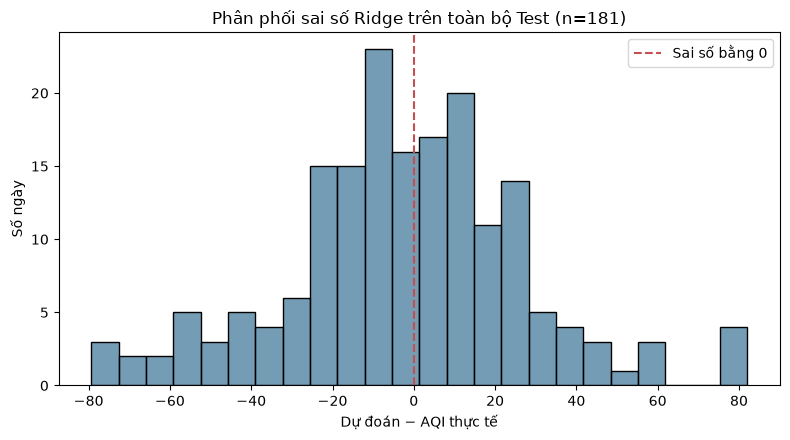

figures saved; line window 2025-01-01 2025-02-14 histogram n 181


In [13]:
selected_test_pred=test_predictions[selected_method]
test_result=pd.DataFrame({'actual':y_test.to_numpy(),'predicted':selected_test_pred},index=X_test.index)
test_result['error']=test_result['predicted']-test_result['actual']
test_result['absolute_error']=test_result['error'].abs()
fig,ax=plt.subplots(figsize=(11,4.5))
window=test_result.iloc[:45]
ax.plot(window.index,window['actual'],label='AQI thực tế',color='#1f77b4',linewidth=1.8)
ax.plot(window.index,window['predicted'],label=f'Dự đoán {selected_method}',color='#e76f51',linewidth=1.6)
ax.set(title=f'AQI trung bình ngày: thực tế và {selected_method} — 45 ngày Test đầu',xlabel='Ngày đích (2025)',ylabel='AQI trung bình ngày')
ax.legend();ax.grid(alpha=.25);fig.autofmt_xdate();fig.tight_layout();fig.savefig(project_root/'output/figures/pred_test_first45.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4.5))
sns.histplot(test_result['error'],bins=24,color='#457b9d',ax=ax)
ax.axvline(0,color='#c44e52',linestyle='--',label='Sai số bằng 0')
ax.set(title=f'Phân phối sai số {selected_method} trên toàn bộ Test (n={len(test_result)})',xlabel='Dự đoán − AQI thực tế',ylabel='Số ngày')
ax.legend();fig.tight_layout();fig.savefig(project_root/'output/figures/pred_test_error_hist.png',dpi=160);plt.show()
print('figures saved; line window',window.index.min().date(),window.index.max().date(),'histogram n',len(test_result))

### Kết luận bước 10.6

Biểu đồ đường minh họa khoảng cố định 01/01–14/02/2025 (45 ngày Test đầu): dự đoán Ridge đi theo biến động chung nhưng mượt hơn thực tế, có những đỉnh/đáy ngắn hạn không bám sát. Histogram dùng toàn bộ 181 ngày Test, thể hiện cả sai số âm và dương; đường đứt tại 0 cho thấy hướng sai số. Hai hình đều ghi rõ phương pháp, phạm vi, trục và cỡ mẫu; MAE/RMSE ở bước 10.5 được tính trên toàn bộ Test, không chỉ 45 ngày minh họa. Bước tiếp theo sẽ lượng hóa độ lệch có dấu và các ngày sai số lớn.

### Bước 10.7 — Phân tích sai số và ngày AQI cao

**Mục tiêu:** Xem thiên lệch, ngày sai số lớn và sai số ở ngày AQI cao.

**Lý do:** MAE/RMSE chung có thể che các ngày khó dự đoán; ngưỡng ngày cao phải xác định từ Train.

**Phương pháp:** Tính sai số có dấu và tuyệt đối, top 5 ngày lỗi lớn, so ngày có AQI mục tiêu >= phân vị 90% của Train với ngày còn lại.

**Kết quả cần quan sát:** Bảng sai số nhóm và ngày khó, không suy diễn nguyên nhân.

In [14]:
high_threshold=float(y_train.quantile(.9))
test_result['high_aqi']=test_result['actual']>=high_threshold
error_summary=test_result.groupby('high_aqi').agg(n=('actual','size'),mean_actual=('actual','mean'),MAE=('absolute_error','mean'),mean_error=('error','mean'),median_absolute_error=('absolute_error','median'))
print('Train 90th percentile AQI target threshold',round(high_threshold,3))
print('SELECTED TEST ERROR mean_error',round(test_result['error'].mean(),3),'median_error',round(test_result['error'].median(),3),'MAE',round(test_result['absolute_error'].mean(),3),'max_absolute_error',round(test_result['absolute_error'].max(),3))
print('HIGH AQI VS OTHER TEST DAYS');print(error_summary.round(3).to_string())
print('TOP 5 ABSOLUTE ERRORS');print(test_result.nlargest(5,'absolute_error')[['actual','predicted','error','absolute_error','high_aqi']].round(3).to_string())
print('Test AQI=500 days',int((test_result['actual']==500).sum()),'test actual max',round(test_result['actual'].max(),3))

Train 90th percentile AQI target threshold 179.046
SELECTED TEST ERROR mean_error -2.417 median_error -2.451 MAE 22.399 max_absolute_error 82.024
HIGH AQI VS OTHER TEST DAYS
            n  mean_actual     MAE  mean_error  median_absolute_error
high_aqi                                                             
False     142      125.104  20.197       5.224                 15.735
True       39      202.850  30.419     -30.236                 25.339
TOP 5 ABSOLUTE ERRORS
              actual  predicted   error  absolute_error  high_aqi
target_date                                                      
2025-02-07    64.083    146.107  82.024          82.024     False
2025-01-10   128.792    209.900  81.108          81.108     False
2025-04-29   201.375    122.061 -79.314          79.314      True
2025-02-27   188.750    111.028 -77.722          77.722      True
2025-06-21    89.708    166.266  76.557          76.557     False
Test AQI=500 days 0 test actual max 233.333


### Kết luận bước 10.7

Trên 181 ngày Test, sai số có dấu (dự đoán − thực tế) trung bình −2,417, trung vị −2,451: thiên lệch gộp hơi thấp; MAE 22,399 và sai số tuyệt đối lớn nhất 82,024. Ngưỡng AQI ngày cao lấy từ phân vị 90% của **Train** là 179,046. Trong 39 ngày Test vượt ngưỡng, MAE 30,419 và sai số trung bình −30,236 (thường dự đoán thấp); 142 ngày còn lại có MAE 20,197 và sai số trung bình +5,224. Năm ngày lỗi tuyệt đối lớn nhất gồm 07/02 (+82,024), 10/01 (+81,108), 29/04 (−79,314), 27/02 (−77,722), 21/06 (+76,557). Test không có ngày AQI trung bình bằng 500; AQI ngày cao nhất 233,333. Dữ liệu cho thấy dự đoán kém hơn ở nhóm ngày AQI cao theo ngưỡng đã định từ Train, nhưng chưa xác định nguyên nhân và không dùng phân tích Test để tối ưu lại.

### Bước 10.8 — Kết quả cuối và lưu thông tin phương pháp

**Mục tiêu:** Chốt bằng chứng Validation/Test và lưu trạng thái để Giai đoạn 11 dùng lại nhất quán.

**Lý do:** Chức năng sau này phải dùng đúng phương pháp, alpha và thứ tự đặc trưng đã cố định; chưa xây dựng chức năng trong bước này.

**Phương pháp:** In quyết định và sai số; lưu metadata JSON, lưu pipeline nếu Ridge được chọn. Không điều chỉnh theo Test.

**Kết quả cần quan sát:** Tệp phương pháp cuối và kết quả kiểm chứng.

In [15]:
from pathlib import Path
import joblib
model_dir=project_root/'output/model';model_dir.mkdir(parents=True,exist_ok=True)
metadata={'selected_method':selected_method,'selection_metric':'Validation MAE, then RMSE','ridge_alpha':chosen_alpha,'ridge_refit':'Train+Validation','features':feature_names,'target':'AQI_target','train_samples':len(X_train),'validation_samples':len(X_val),'test_samples':len(X_test),'validation_metrics':validation_table[['MAE','RMSE']].round(6).to_dict(orient='index'),'test_metrics':test_table[['MAE','RMSE']].round(6).to_dict(orient='index'),'test_only_first_half_2025':True}
metadata_path=model_dir/'aqi_next_day_model_metadata.json'
metadata_path.write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
artifact_path=model_dir/'aqi_next_day_ridge.joblib'
if selected_method=='Ridge':
    joblib.dump(final_ridge_pipeline,artifact_path)
print('selected',selected_method,'validation',validation_table.loc[selected_method,['MAE','RMSE']].round(4).to_dict(),'test',test_table.loc[selected_method,['MAE','RMSE']].round(4).to_dict())
print('test persistence',test_table.loc['Persistence',['MAE','RMSE']].round(4).to_dict(),'test weekly',test_table.loc['Weekly',['MAE','RMSE']].round(4).to_dict())
print('metadata',metadata_path.relative_to(project_root),'ridge artifact saved',artifact_path.exists() if selected_method=='Ridge' else False)
print('No test-based reselection or user-input function implemented.')

selected Ridge validation {'MAE': 23.3883, 'RMSE': 34.8658} test {'MAE': 22.3992, 'RMSE': 29.6577}
test persistence {'MAE': 24.7083, 'RMSE': 32.0491} test weekly {'MAE': 37.3027, 'RMSE': 49.1494}
metadata output\model\aqi_next_day_model_metadata.json ridge artifact saved True
No test-based reselection or user-input function implemented.


### Kết luận bước 10.8

**Kết luận Giai đoạn 10:** Ridge với alpha 0,1 được chọn bằng Validation (MAE 23,3883; RMSE 34,8658), tốt hơn Persistence 24,8181/38,7292 và Weekly 41,2527/58,3719 trên cùng 351 ngày. Sau khi fit lại cả StandardScaler và Ridge trên Train + Validation (1.053 mẫu), Test 181 ngày cho MAE 22,3992 và RMSE 29,6577; thấp hơn Persistence 24,7083/32,0491 và Weekly 37,3027/49,1494. Đây là cải thiện thực tế trong phép đánh giá cuốn chiếu một ngày, nhưng sai số còn đáng kể, nhất là 39 ngày AQI cao (MAE 30,419; trung bình dự đoán thấp 30,236 điểm). Test chỉ có tháng 1–6/2025; dữ liệu thiếu ngày đã bị loại cửa sổ, mô hình chỉ dùng AQI bảy ngày trước, chưa đánh giá tính ổn định ngoài khoảng này. Metadata và Pipeline Ridge đã được lưu trong `output/model/` để Giai đoạn 11 dùng đúng 7 đặc trưng; chưa xây dựng chức năng nhập liệu. Test không được dùng để thay đổi alpha, phương pháp hay fit.

## Giai đoạn 11 — Chức năng dự đoán ngày kế tiếp

Chỉ dùng Pipeline Ridge alpha 0,1 đã được chọn và đánh giá ở Giai đoạn 10, tải từ file do chính project tạo ra. Người dùng nhập ngày cuối đã quan sát và bảy AQI trung bình ngày theo thứ tự **cũ nhất → mới nhất**. Hàm không fit lại mô hình, không dùng AQI tương lai, không cắt dự đoán về 0–500 và không phân loại mức AQI khi thiếu tài liệu nguồn. Kết quả là AQI **trung bình ngày**, không phải từng giờ hay cảnh báo chính thức.

### Bước 11.1 — Kiểm tra và tải Pipeline đã lưu

**Mục tiêu:** Xác nhận artifact, metadata, thứ tự đặc trưng và khả năng dự đoán.

**Lý do:** Chức năng phải dùng đúng mô hình được chọn, không tải joblib không rõ nguồn.

**Phương pháp:** Kiểm tra đường dẫn trong output/model của project, đọc metadata JSON, tải joblib đã tạo ở Giai đoạn 10 và xác minh Pipeline/scaler/Ridge.

**Kết quả cần quan sát:** Tên mô hình, alpha, bảy đặc trưng, số mẫu fit và một dự đoán kiểm tra.

In [16]:
import json
import joblib
import math
import re
from datetime import date,timedelta
from numbers import Real
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

trusted_model_dir=(project_root/'output/model').resolve()
model_path=(trusted_model_dir/'aqi_next_day_ridge.joblib').resolve()
metadata_path=(trusted_model_dir/'aqi_next_day_model_metadata.json').resolve()
assert model_path.parent==trusted_model_dir and metadata_path.parent==trusted_model_dir
assert model_path.is_file() and metadata_path.is_file()
model_metadata=json.loads(metadata_path.read_text(encoding='utf-8'))
assert model_metadata['selected_method']=='Ridge' and model_metadata['ridge_alpha']==0.1
assert model_metadata['features']==[f'AQI_lag_{k}' for k in range(1,8)]
loaded_pipeline=joblib.load(model_path)  # Chỉ tải artifact cố định do chính notebook này tạo.
assert isinstance(loaded_pipeline,Pipeline)
assert list(loaded_pipeline.named_steps)==['scaler','ridge']
assert isinstance(loaded_pipeline.named_steps['scaler'],StandardScaler)
assert isinstance(loaded_pipeline.named_steps['ridge'],Ridge)
assert loaded_pipeline.named_steps['scaler'].n_features_in_==7
assert loaded_pipeline.named_steps['scaler'].n_samples_seen_==1053
assert loaded_pipeline.named_steps['ridge'].alpha==model_metadata['ridge_alpha']
assert loaded_pipeline.feature_names_in_.tolist()==model_metadata['features']
train_feature_min=float(X_train_val.min().min());train_feature_max=float(X_train_val.max().max())
train_target_min=float(y_train_val.min());train_target_max=float(y_train_val.max())
probe=float(loaded_pipeline.predict(X_test.iloc[[0]])[0])
print('model',model_path.relative_to(project_root),'metadata',metadata_path.relative_to(project_root))
print('pipeline steps',list(loaded_pipeline.named_steps),'alpha',loaded_pipeline.named_steps['ridge'].alpha,'fit samples',loaded_pipeline.named_steps['scaler'].n_samples_seen_)
print('features',model_metadata['features'])
print('observed fit feature range',train_feature_min,train_feature_max,'target range',train_target_min,train_target_max)
print('one numeric prediction',round(probe,6),'Test MAE/RMSE',model_metadata['test_metrics']['Ridge'])

model output\model\aqi_next_day_ridge.joblib metadata output\model\aqi_next_day_model_metadata.json
pipeline steps ['scaler', 'ridge'] alpha 0.1 fit samples 1053.0
features ['AQI_lag_1', 'AQI_lag_2', 'AQI_lag_3', 'AQI_lag_4', 'AQI_lag_5', 'AQI_lag_6', 'AQI_lag_7']
observed fit feature range 42.875 500.0 target range 42.875 500.0
one numeric prediction 164.687124 Test MAE/RMSE {'MAE': 22.399229, 'RMSE': 29.65768}


### Kết luận bước 11.1

Cả artifact và metadata đều tồn tại trong `output/model/` của project. Metadata xác nhận phương pháp được chọn là Ridge, alpha 0,1, bảy đặc trưng theo thứ tự `AQI_lag_1`…`AQI_lag_7`, Test MAE 22,399229 và RMSE 29,65768. Artifact tải được bằng joblib, là Pipeline gồm `scaler` (StandardScaler) và `ridge` (Ridge), đã fit trên 1.053 mẫu Train + Validation, nhận đúng bảy đặc trưng; dự đoán kiểm tra trả số 164,687124. Khoảng AQI đặc trưng và mục tiêu quan sát trong dữ liệu fit đều 42,875–500,0. Chỉ tải đường dẫn artifact cố định do project tạo, không nhận file joblib do người dùng đưa vào.

### Bước 11.2 — Hàm dự đoán từ bảy ngày AQI

**Mục tiêu:** Tạo hàm tái sử dụng với kiểm tra đầu vào và ánh xạ lag đúng thứ tự.

**Lý do:** Đầu vào sai phải có lỗi rõ ràng; dự đoán giữ giá trị số đầy đủ và không fit lại.

**Phương pháp:** Kiểm tra ISO date, bảy số thực hữu hạn không âm; tạo DataFrame lag1 là giá trị mới nhất; gọi Pipeline.predict và trả dict có ngày, AQI, chỉ số Test, cảnh báo.

**Kết quả cần quan sát:** Chữ ký hàm và ánh xạ lag được công bố.

In [17]:
def predict_next_day_aqi(last_date,aqi_history):
    """Dự đoán AQI trung bình ngày kế tiếp từ 7 AQI ngày liên tiếp, cũ→mới.

    last_date: chuỗi YYYY-MM-DD của ngày cuối đã có AQI thực tế.
    aqi_history: list/tuple/ndarray gồm đúng 7 số, cũ nhất đến mới nhất.
    """
    if not isinstance(last_date,str) or not re.fullmatch(r'\d{4}-\d{2}-\d{2}',last_date):
        raise ValueError('last_date phải là chuỗi ngày YYYY-MM-DD, ví dụ 2025-06-30.')
    try:
        observed_date=date.fromisoformat(last_date)
        target_date=observed_date+timedelta(days=1)
    except (ValueError,OverflowError) as exc:
        raise ValueError('last_date không phải ngày hợp lệ hoặc không xác định được ngày kế tiếp.') from exc
    if not isinstance(aqi_history,(list,tuple,np.ndarray)) or len(aqi_history)!=7:
        raise ValueError('aqi_history phải có đúng 7 giá trị AQI theo thứ tự cũ nhất đến mới nhất.')
    values=[]
    for position,value in enumerate(aqi_history,1):
        if isinstance(value,(bool,np.bool_)) or not isinstance(value,Real):
            raise ValueError(f'AQI thứ {position} phải là số thực, không phải chuỗi hoặc boolean.')
        number=float(value)
        if not math.isfinite(number):
            raise ValueError(f'AQI thứ {position} phải hữu hạn; NaN/Infinity không hợp lệ.')
        if number<0:
            raise ValueError(f'AQI thứ {position} không được âm.')
        values.append(number)
    feature_frame=pd.DataFrame([{f'AQI_lag_{k}':values[-k] for k in range(1,8)}],columns=model_metadata['features'])
    prediction=float(loaded_pipeline.predict(feature_frame)[0])
    warnings=[
        'Bảy giá trị phải thực sự thuộc bảy ngày lịch liên tiếp; với chỉ ngày cuối và bảy số, hàm không thể tự xác minh nguồn/ngày của từng số.',
        'Dự đoán là AQI trung bình ngày, không phải AQI từng giờ hay cảnh báo sức khỏe/môi trường chính thức.',
        'MAE/RMSE chỉ được kiểm chứng trên Test tháng 1–6/2025; mô hình có xu hướng dự đoán thấp ở nhóm ngày AQI cao.'
    ]
    if min(values)<train_feature_min or max(values)>train_feature_max:
        warnings.append(f'Đầu vào ngoài khoảng AQI đặc trưng đã thấy khi fit [{train_feature_min:.3f}, {train_feature_max:.3f}]; dự đoán là ngoại suy.')
    if prediction<0 or prediction>train_target_max or prediction<train_target_min:
        warnings.append(f'Dự đoán ngoài khoảng AQI ngày đã thấy khi fit [{train_target_min:.3f}, {train_target_max:.3f}]; giữ nguyên giá trị, không cắt ngưỡng.')
    input_days=[{'date':(observed_date-timedelta(days=6-i)).isoformat(),'AQI_daily':value} for i,value in enumerate(values)]
    return {'last_observed_date':observed_date.isoformat(),'prediction_date':target_date.isoformat(),
            'input_days':input_days,'predicted_AQI_daily':prediction,'model':'Ridge Regression',
            'alpha':model_metadata['ridge_alpha'],'test_metrics':model_metadata['test_metrics']['Ridge'],
            'warnings':warnings}

print('function predict_next_day_aqi(last_date, aqi_history) ready')
print('input order: oldest -> newest; feature order:',model_metadata['features'])
print('mapping: AQI_lag_1 = aqi_history[-1]; AQI_lag_7 = aqi_history[0]')

function predict_next_day_aqi(last_date, aqi_history) ready
input order: oldest -> newest; feature order: ['AQI_lag_1', 'AQI_lag_2', 'AQI_lag_3', 'AQI_lag_4', 'AQI_lag_5', 'AQI_lag_6', 'AQI_lag_7']
mapping: AQI_lag_1 = aqi_history[-1]; AQI_lag_7 = aqi_history[0]


### Kết luận bước 11.2

Hàm `predict_next_day_aqi(last_date, aqi_history)` đã được định nghĩa và nhận ngày cuối dạng `YYYY-MM-DD` cùng đúng bảy AQI theo thứ tự cũ nhất→mới nhất. Ánh xạ đã in rõ: `AQI_lag_1 = aqi_history[-1]` và `AQI_lag_7 = aqi_history[0]`, DataFrame dùng đúng thứ tự cột metadata. Hàm kiểm tra kiểu số, NaN/Infinity, AQI âm và ngày; trả ngày dự đoán, bảy ngày đầu vào, AQI dự đoán đầy đủ, mô hình, chỉ số Test và cảnh báo. Đầu vào ngoài khoảng quan sát khi fit được cảnh báo chứ không tự sửa; dự đoán cũng không bị cắt ngưỡng. Hàm chỉ gọi `predict()`, không có `fit()`; các kiểm thử thực tế tiếp theo sẽ xác nhận hành vi.

### Bước 11.3 — Kiểm tra đầu vào hợp lệ và tính nhất quán

**Mục tiêu:** Xác nhận hàm dự đoán khớp trực tiếp Pipeline đã lưu trên một mẫu Test thật.

**Lý do:** So sánh hai đường dự đoán phát hiện đảo thứ tự lag hoặc sửa giá trị đầu vào.

**Phương pháp:** Lấy một hàng Test, đảo lag7→lag1 thành lịch sử cũ→mới; gọi hàm và Pipeline, kiểm tra ngày và np.isclose.

**Kết quả cần quan sát:** Ngày đích, bảy ngày đầu vào và hai dự đoán khớp.

In [18]:
test_target=X_test.index[0]
test_last_date=(test_target-pd.Timedelta(days=1)).date().isoformat()
test_history=[float(X_test.iloc[0][f'AQI_lag_{k}']) for k in range(7,0,-1)]
function_result=predict_next_day_aqi(test_last_date,test_history)
direct_prediction=float(loaded_pipeline.predict(X_test.iloc[[0]])[0])
assert function_result['prediction_date']==test_target.date().isoformat()
assert len(function_result['input_days'])==7
assert np.isclose(function_result['predicted_AQI_daily'],direct_prediction,atol=1e-10,rtol=1e-12)
print('Test sample target',test_target.date(),'last observed',test_last_date)
print('input dates and AQI');display(pd.DataFrame(function_result['input_days']).round(3))
print('function prediction',function_result['predicted_AQI_daily'],'direct Pipeline prediction',direct_prediction,'difference',function_result['predicted_AQI_daily']-direct_prediction)
print('model',function_result['model'],'test metrics',function_result['test_metrics'])

Test sample target 2025-01-01 last observed 2024-12-31
input dates and AQI


,date,AQI_daily
0,2024-12-25,212.542
1,2024-12-26,205.042
2,2024-12-27,136.083
3,2024-12-28,118.333
4,2024-12-29,180.500
5,2024-12-30,193.708
6,2024-12-31,173.167


function prediction 164.68712363740414 direct Pipeline prediction 164.68712363740414 difference 0.0
model Ridge Regression test metrics {'MAE': 22.399229, 'RMSE': 29.65768}


### Kết luận bước 11.3

Một mẫu Test thực có ngày đích 01/01/2025, ngày AQI cuối 31/12/2024 và bảy ngày đầu vào 25–31/12/2024. Hàm trả dự đoán 164,68712363740414, đúng bằng dự đoán trực tiếp từ Pipeline đã lưu (chênh 0 trong phép kiểm), ngày đích và bảy ngày gắn nhãn đều đúng. Đây là kiểm tra tính nhất quán của cách đảo lịch sử cũ→mới thành lag1→lag7; giá trị AQI thực của ngày đích không được đưa vào hàm. Thông tin Test đi kèm kết quả là MAE 22,399229 và RMSE 29,65768 đã tính ở Giai đoạn 10.

### Bước 11.4 — Kiểm thử dữ liệu sai và cảnh báo ngoài phạm vi

**Mục tiêu:** Đảm bảo thiếu/âm/NaN/Infinity/không phải số/ngày sai được báo rõ.

**Lý do:** Hàm không được âm thầm thay giá trị sai; đầu vào ngoài khoảng đã fit cần cảnh báo.

**Phương pháp:** Gọi hàm với các trường hợp sai, assert ValueError; kiểm tra một đầu vào không âm nhưng ngoài khoảng fit cho cảnh báo ngoại suy.

**Kết quả cần quan sát:** Bảng lỗi mong đợi và thông báo ngoài phạm vi.

In [19]:
bad_cases={
    'chỉ 6 giá trị':('2025-06-30',[100.0]*6),
    'AQI âm':('2025-06-30',[100.0]*6+[-1.0]),
    'AQI NaN':('2025-06-30',[100.0]*6+[float('nan')]),
    'AQI Infinity':('2025-06-30',[100.0]*6+[float('inf')]),
    'AQI không phải số':('2025-06-30',[100.0]*6+['cao']),
    'ngày không tồn tại':('2025-02-30',[100.0]*7),
    'ngày sai định dạng':('30/06/2025',[100.0]*7),
}
for label,(last_day,history) in bad_cases.items():
    try:
        predict_next_day_aqi(last_day,history)
    except ValueError as exc:
        print(label,'->',str(exc))
    else:
        raise AssertionError(f'Không phát hiện lỗi: {label}')
outside_result=predict_next_day_aqi('2025-06-30',[train_feature_max+1.0]*7)
assert any('ngoài khoảng AQI đặc trưng' in item for item in outside_result['warnings'])
print('outside-fit-range input -> warning:',[item for item in outside_result['warnings'] if 'ngoài khoảng' in item])
print('invalid cases caught',len(bad_cases),'no values silently replaced')

chỉ 6 giá trị -> aqi_history phải có đúng 7 giá trị AQI theo thứ tự cũ nhất đến mới nhất.
AQI âm -> AQI thứ 7 không được âm.
AQI NaN -> AQI thứ 7 phải hữu hạn; NaN/Infinity không hợp lệ.
AQI Infinity -> AQI thứ 7 phải hữu hạn; NaN/Infinity không hợp lệ.
AQI không phải số -> AQI thứ 7 phải là số thực, không phải chuỗi hoặc boolean.
ngày không tồn tại -> last_date không phải ngày hợp lệ hoặc không xác định được ngày kế tiếp.
ngày sai định dạng -> last_date phải là chuỗi ngày YYYY-MM-DD, ví dụ 2025-06-30.
outside-fit-range input -> warning: ['Đầu vào ngoài khoảng AQI đặc trưng đã thấy khi fit [42.875, 500.000]; dự đoán là ngoại suy.']
invalid cases caught 7 no values silently replaced


### Kết luận bước 11.4

Bảy trường hợp sai đều bị chặn bằng `ValueError` rõ ràng: thiếu một giá trị, AQI âm, NaN, Infinity, chuỗi thay số, ngày không tồn tại và ngày sai định dạng. Không trường hợp nào được thay âm thầm bằng giá trị mặc định. Trường hợp bảy giá trị 501 (ngoài khoảng đặc trưng đã thấy khi fit 42,875–500) không bị giả định là dữ liệu sai vì thang đo nguồn chưa xác minh; hàm trả cảnh báo ngoại suy rõ ràng. Giá trị dự đoán không bị cắt về 0–500. Kiểm thử này xác nhận xử lý lỗi, không dùng để chọn hoặc điều chỉnh mô hình.

### Bước 11.5 — Demo dự đoán với bảy ngày thực tế

**Mục tiêu:** Minh họa cách nhập và đọc kết quả cho một ngày sau dữ liệu quan sát.

**Lý do:** Demo dùng bảy AQI ngày thực, không dùng giá trị đích tương lai.

**Phương pháp:** Lấy AQI ngày 24–30/06/2025 từ bảng ngày Giai đoạn 9; gọi hàm cho 01/07/2025 và hiển thị đầu vào, dự đoán, Test metrics, cảnh báo.

**Kết quả cần quan sát:** Bảng bảy ngày đầu vào và kết quả minh họa rõ ràng.

In [20]:
# Có thể thay hai biến sau bằng ngày cuối và 7 AQI ngày thật khác, theo thứ tự cũ→mới.
user_last_date='2025-06-30'
user_aqi_history=daily.loc['2025-06-24':'2025-06-30','AQI_daily'].astype(float).tolist()
assert len(user_aqi_history)==7 and daily.loc['2025-06-24':'2025-06-30','valid_day'].all()
demo_result=predict_next_day_aqi(user_last_date,user_aqi_history)
print('Bảy ngày AQI đã nhập (cũ -> mới)');display(pd.DataFrame(demo_result['input_days']).round(3))
print('Ngày dự đoán:',demo_result['prediction_date'])
print('AQI trung bình ngày dự đoán:',round(demo_result['predicted_AQI_daily'],2),'(giá trị đầy đủ:',demo_result['predicted_AQI_daily'],')')
print('Mô hình:',demo_result['model'],'alpha:',demo_result['alpha'])
print('Test MAE/RMSE:',demo_result['test_metrics'])
print('Lưu ý:');[print('-',note) for note in demo_result['warnings']]
print('Không có AQI thực tế của ngày 01/07/2025 trong dataset để kiểm chứng demo này.')

Bảy ngày AQI đã nhập (cũ -> mới)


,date,AQI_daily
0,2025-06-24,126.917
1,2025-06-25,98.250
2,2025-06-26,100.417
3,2025-06-27,93.083
4,2025-06-28,85.958
5,2025-06-29,111.167
6,2025-06-30,88.792


Ngày dự đoán: 2025-07-01
AQI trung bình ngày dự đoán: 89.57 (giá trị đầy đủ: 89.57344319939507 )
Mô hình: Ridge Regression alpha: 0.1
Test MAE/RMSE: {'MAE': 22.399229, 'RMSE': 29.65768}
Lưu ý:
- Bảy giá trị phải thực sự thuộc bảy ngày lịch liên tiếp; với chỉ ngày cuối và bảy số, hàm không thể tự xác minh nguồn/ngày của từng số.
- Dự đoán là AQI trung bình ngày, không phải AQI từng giờ hay cảnh báo sức khỏe/môi trường chính thức.
- MAE/RMSE chỉ được kiểm chứng trên Test tháng 1–6/2025; mô hình có xu hướng dự đoán thấp ở nhóm ngày AQI cao.
Không có AQI thực tế của ngày 01/07/2025 trong dataset để kiểm chứng demo này.


### Kết luận bước 11.5

Demo dùng bảy AQI trung bình ngày thực từ 24–30/06/2025 theo thứ tự cũ→mới: 126,917; 98,250; 100,417; 93,083; 85,958; 111,167; 88,792. Với ngày cuối 30/06/2025, hàm dự đoán AQI **trung bình ngày 01/07/2025 là 89,57** (giá trị tính đầy đủ 89,57344319939507) bằng Ridge alpha 0,1. Kết quả kèm Test MAE 22,399229, RMSE 29,65768 và các cảnh báo về tính liên tiếp của dữ liệu nhập, phạm vi Test chỉ nửa đầu 2025, xu hướng dự đoán thấp ở ngày AQI cao và việc không dùng như cảnh báo chính thức. Dataset không có AQI thực của 01/07/2025 để kiểm chứng riêng demo; không trình bày 89,57 như giá trị thực hay đảm bảo chính xác.

## Tổng kết Notebook 2 — Dự đoán AQI trung bình ngày tiếp theo

**Bài toán và dữ liệu.** Từ AQI trung bình của bảy ngày lịch liên tiếp ngay trước ngày đích, dự đoán AQI trung bình **ngày kế tiếp**; không dự đoán từng giờ. Dữ liệu sạch của Notebook 1 được tổng hợp theo ngày địa phương. Một ngày chỉ hợp lệ khi có 24 mốc giờ duy nhất và 24 AQI hợp lệ. Trong 1.265 ngày lịch có 1.262 ngày hợp lệ; ba ngày không hợp lệ là 01/07/2022 (22/24 giờ AQI), 31/12/2023 (không có bản ghi), 01/12/2024 (23/24). Lịch đầy đủ và bảy lag tạo **1.234 mẫu**, không nối qua ngày không hợp lệ, không điền hoặc nội suy AQI.

**Chia theo thời gian.** Train gồm **702 mẫu** (20/01/2022–30/12/2023), Validation **351 mẫu** (08/01–31/12/2024), Test **181 mẫu** (01/01–30/06/2025). Bảy đặc trưng là `AQI_lag_1` đến `AQI_lag_7`; mục tiêu `AQI_target` không thuộc đầu vào. Test không dùng để chọn phương pháp/alpha hoặc fit preprocessing.

**So sánh phương pháp.** Persistence dự đoán bằng `AQI_lag_1`, Weekly bằng `AQI_lag_7`. Ridge dùng Pipeline StandardScaler–Ridge; alpha **0,1** được chọn từ 0,1; 1; 10; 100 bằng MAE Validation (RMSE phân xử khi cần). Ridge được chọn trên Validation rồi fit lại cả scaler và Ridge trên Train + Validation (**1.053 mẫu**). Kết quả:

| Phương pháp | Validation MAE | Validation RMSE | Test MAE | Test RMSE |
|---|---:|---:|---:|---:|
| Ridge, alpha 0,1 | **23,3883** | **34,8658** | **22,3992** | **29,6577** |
| Persistence | 24,8181 | 38,7292 | 24,7083 | 32,0491 |
| Weekly | 41,2527 | 58,3719 | 37,3027 | 49,1494 |

Ridge thấp hơn hai baseline trong Test này, nhưng sai số còn đáng kể. Trên **39 ngày AQI cao** theo ngưỡng phân vị 90% của Train (179,046), MAE Test là **30,419** và sai số có dấu trung bình **−30,236**: mô hình thường dự đoán thấp. Toàn Test có sai số trung bình **−2,417**, Test chỉ bao phủ tháng 1–6/2025 và không có ngày AQI trung bình bằng 500. Đây là đánh giá **cuốn chiếu một ngày** dùng AQI thực tế của bảy ngày trước; không phải dự báo nhiều ngày liên tiếp bằng cách đưa dự đoán cũ vào làm đầu vào.

**Chức năng sử dụng.** Sau khi chạy notebook từ đầu, có thể gọi:

```python
result = predict_next_day_aqi(
    last_date='2025-06-30',
    aqi_history=daily.loc['2025-06-24':'2025-06-30', 'AQI_daily'].tolist()
)
print(result['prediction_date'], round(result['predicted_AQI_daily'], 2))
```

Bảy số đầu vào phải theo thứ tự **cũ nhất → mới nhất**; hàm tự ánh xạ giá trị mới nhất vào `AQI_lag_1`. Để thử dữ liệu của mình, sửa `user_last_date` và `user_aqi_history` trong cell demo 11.5 rồi chạy lại cell đó. Hàm chỉ gọi `predict()` của Pipeline đã lưu, không fit lại; trả ngày dự đoán, bảy ngày và AQI đã dùng, giá trị dự đoán đầy đủ, tên mô hình, MAE/RMSE Test và cảnh báo. Demo từ bảy ngày thực 24–30/06/2025 cho **AQI trung bình ngày 01/07/2025 dự đoán 89,57**; dataset không có AQI thực của ngày này để đối chiếu.

**Kiểm thử.** Dự đoán của hàm với mẫu Test 01/01/2025 là **164,68712363740414**, khớp chính xác Pipeline gọi trực tiếp (chênh 0). Bảy đầu vào sai (thiếu giá trị, âm, NaN, Infinity, không phải số, ngày không tồn tại, ngày sai định dạng) đều bị từ chối với thông báo rõ. Giá trị không âm nhưng ngoài khoảng đặc trưng từng thấy khi fit **42,875–500** nhận cảnh báo ngoại suy, không tự bị thay hoặc cắt. Hàm không thể tự xác minh bảy số người nhập thật sự được lấy từ bảy ngày liên tiếp vì chỉ nhận một ngày cuối và bảy số; người dùng phải bảo đảm điều này.

**Giới hạn và hướng phát triển.** Test chỉ có nửa đầu 2025; kết quả không bảo đảm chính xác cho mọi ngày, đặc biệt ngày AQI cao hoặc đầu vào ngoài phạm vi đã quan sát. Chưa kiểm chứng nguồn trạm, công thức AQI hoặc hiệu quả ở các giai đoạn tương lai; mô hình chỉ dùng AQI quá khứ và bỏ các ngày thiếu khỏi cửa sổ. Có thể đánh giá thêm trên các năm sau, phân tích sai số theo điều kiện khác và xem xét dữ liệu đầu vào có sẵn tại thời điểm dự đoán, nhưng mọi thay đổi cần đánh giá ngoài mẫu mới. **Không sử dụng dự đoán như một cảnh báo sức khỏe hoặc môi trường chính thức.**